  CREDIT SCORING MODEL — Give Me Some Credit

[INFO] Training set : 150,000 rows × 11 cols
[INFO] Test set     : 101,503 rows × 11 cols

── Target distribution ──────────────────────────
SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64
Positive (distress) rate: 6.68%

── Missing values (training) ────────────────────
MonthlyIncome         29731
NumberOfDependents     3924
dtype: int64

── Model Comparison ─────────────────────────────
  Logistic Regression     Accuracy=0.7725  ROC-AUC=0.8024
  Decision Tree           Accuracy=0.7977  ROC-AUC=0.8539
  Random Forest           Accuracy=0.8283  ROC-AUC=0.8647
  Gradient Boosting       Accuracy=0.9372  ROC-AUC=0.8698

✅ Best model: Gradient Boosting  (AUC=0.8698)

── Classification Report ────────────────────────
              precision    recall  f1-score   support

 No Distress       0.94      0.99      0.97     27995
    Distress       0.59      0.19      0.29      2005

    accuracy                           0.94     3

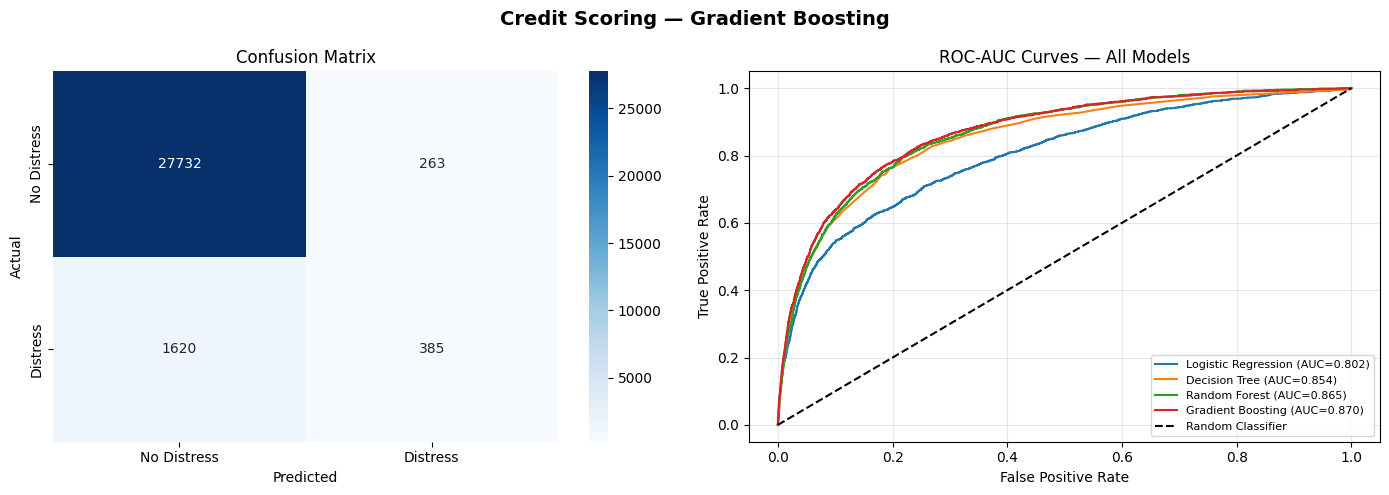


[INFO] Plot saved → credit_scoring_results.png


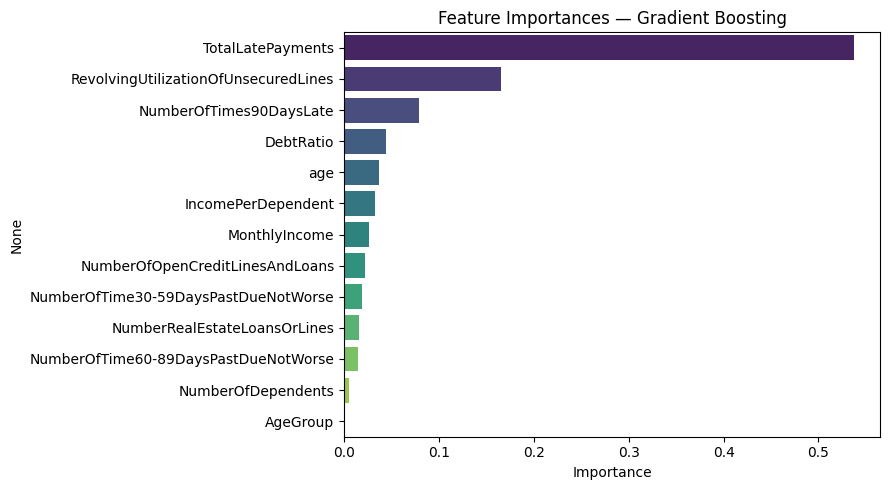

[INFO] Feature importance plot saved → feature_importance.png

── Top 5 Features ───────────────────────────────
TotalLatePayments                       0.538008
RevolvingUtilizationOfUnsecuredLines    0.165771
NumberOfTimes90DaysLate                 0.079396
DebtRatio                               0.043672
age                                     0.036339
dtype: float64


In [1]:
"""
=============================================================
  TASK 1: Credit Scoring Model  — Give Me Some Credit (Kaggle)
  Predict probability of financial distress in next 2 years
=============================================================
"""

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, classification_report, roc_auc_score,
    roc_curve, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# ─────────────────────────────────────────
# 1. LOAD DATA
# ─────────────────────────────────────────
print("=" * 60)
print("  CREDIT SCORING MODEL — Give Me Some Credit")
print("=" * 60)

train_df = pd.read_csv("cs-training.csv", index_col=0)
test_df  = pd.read_csv("cs-test.csv",     index_col=0)

print(f"\n[INFO] Training set : {train_df.shape[0]:,} rows × {train_df.shape[1]} cols")
print(f"[INFO] Test set     : {test_df.shape[0]:,} rows × {test_df.shape[1]} cols")

# ─────────────────────────────────────────
# 2. BASIC EDA
# ─────────────────────────────────────────
print("\n── Target distribution ──────────────────────────")
target_counts = train_df["SeriousDlqin2yrs"].value_counts()
print(target_counts)
print(f"Positive (distress) rate: {target_counts[1] / len(train_df):.2%}")

print("\n── Missing values (training) ────────────────────")
missing = train_df.isnull().sum()
print(missing[missing > 0])

# ─────────────────────────────────────────
# 3. FEATURE ENGINEERING
# ─────────────────────────────────────────
FEATURE_COLS = [
    "RevolvingUtilizationOfUnsecuredLines",
    "age",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents",
]
TARGET = "SeriousDlqin2yrs"

def engineer_features(df):
    df = df.copy()
    # Derived features
    df["TotalLatePayments"] = (
        df["NumberOfTime30-59DaysPastDueNotWorse"]
        + df["NumberOfTime60-89DaysPastDueNotWorse"]
        + df["NumberOfTimes90DaysLate"]
    )
    df["IncomePerDependent"] = df["MonthlyIncome"] / (df["NumberOfDependents"] + 1)
    df["AgeGroup"] = pd.cut(df["age"], bins=[0, 30, 45, 60, 120],
                            labels=[0, 1, 2, 3]).astype(float)
    return df

train_df = engineer_features(train_df)
test_df  = engineer_features(test_df)

FEATURE_COLS_ENG = FEATURE_COLS + ["TotalLatePayments", "IncomePerDependent", "AgeGroup"]

X = train_df[FEATURE_COLS_ENG]
y = train_df[TARGET]

X_test_final = test_df[FEATURE_COLS_ENG]

# ─────────────────────────────────────────
# 4. TRAIN / VALIDATION SPLIT
# ─────────────────────────────────────────
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# ─────────────────────────────────────────
# 5. BUILD PIPELINES
# ─────────────────────────────────────────
imputer   = SimpleImputer(strategy="median")
scaler    = StandardScaler()

models = {
    "Logistic Regression": Pipeline([
        ("imputer", imputer),
        ("scaler",  scaler),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
    ]),
    "Decision Tree": Pipeline([
        ("imputer", imputer),
        ("clf", DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42)),
    ]),
    "Random Forest": Pipeline([
        ("imputer", imputer),
        ("clf", RandomForestClassifier(
            n_estimators=200, max_depth=10,
            class_weight="balanced", n_jobs=-1, random_state=42
        )),
    ]),
    "Gradient Boosting": Pipeline([
        ("imputer", imputer),
        ("clf", GradientBoostingClassifier(
            n_estimators=200, learning_rate=0.05,
            max_depth=5, subsample=0.8, random_state=42
        )),
    ]),
}

# ─────────────────────────────────────────
# 6. TRAIN + EVALUATE ALL MODELS
# ─────────────────────────────────────────
print("\n── Model Comparison ─────────────────────────────")
results = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    y_pred      = pipe.predict(X_val)
    y_prob      = pipe.predict_proba(X_val)[:, 1]
    acc         = accuracy_score(y_val, y_pred)
    auc         = roc_auc_score(y_val, y_prob)
    results[name] = {"pipe": pipe, "acc": acc, "auc": auc,
                     "y_pred": y_pred, "y_prob": y_prob}
    print(f"  {name:<22}  Accuracy={acc:.4f}  ROC-AUC={auc:.4f}")

# Pick best model by AUC
best_name = max(results, key=lambda k: results[k]["auc"])
best      = results[best_name]
print(f"\n✅ Best model: {best_name}  (AUC={best['auc']:.4f})")

# ─────────────────────────────────────────
# 7. DETAILED REPORT FOR BEST MODEL
# ─────────────────────────────────────────
print("\n── Classification Report ────────────────────────")
print(classification_report(y_val, best["y_pred"],
                            target_names=["No Distress", "Distress"]))
print(f"ROC-AUC Score : {best['auc']:.4f}")
print(f"Accuracy      : {best['acc']:.4f}")

# ─────────────────────────────────────────
# 8. PLOTS
# ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f"Credit Scoring — {best_name}", fontsize=14, fontweight="bold")

# --- Confusion Matrix ---
cm = confusion_matrix(y_val, best["y_pred"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["No Distress", "Distress"],
            yticklabels=["No Distress", "Distress"])
axes[0].set_title("Confusion Matrix")
axes[0].set_ylabel("Actual")
axes[0].set_xlabel("Predicted")

# --- ROC Curves for ALL models ---
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_val, r["y_prob"])
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={r['auc']:.3f})")

axes[1].plot([0, 1], [0, 1], "k--", label="Random Classifier")
axes[1].set_title("ROC-AUC Curves — All Models")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("credit_scoring_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("\n[INFO] Plot saved → credit_scoring_results.png")

# ─────────────────────────────────────────
# 9. FEATURE IMPORTANCE (if tree-based)
# ─────────────────────────────────────────
best_clf = best["pipe"].named_steps["clf"]
if hasattr(best_clf, "feature_importances_"):
    fi = pd.Series(best_clf.feature_importances_, index=FEATURE_COLS_ENG)
    fi = fi.sort_values(ascending=False)

    plt.figure(figsize=(9, 5))
    sns.barplot(x=fi.values, y=fi.index, palette="viridis")
    plt.title(f"Feature Importances — {best_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("[INFO] Feature importance plot saved → feature_importance.png")
    print("\n── Top 5 Features ───────────────────────────────")
    print(fi.head())